# 02 Single node

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().parent
FIGURES = ANALYSIS_DIR / 'figures'
sys.path.insert(0, str(ANALYSIS_DIR))

from src.data_loader import load_iperf, load_single_node
from src.statistics import saturation_rate, slo_capacity, summarize

plt.rcParams.update(
    {
        'figure.figsize': (7, 4),
        'figure.dpi': 110,
        'savefig.dpi': 200,
        'savefig.bbox': 'tight',
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.grid': True,
        'grid.alpha': 0.3,
    }
)
SINGLE, MULTI = '#2a78d6', '#eb6834'
pd.set_option('display.float_format', '{:.3f}'.format)

In [2]:
SLOS_MS = [1, 10, 100]
SATURATION_TOLERANCE = 0.95

## Part 1: Network (iperf3, UDP, 10 s × 10 runs)

In [3]:
iperf = load_iperf()
net = summarize(
    iperf,
    'target_mbps',
    ['goodput_mbps', 'lost_percent', 'jitter_ms', 'client_cpu', 'server_cpu'],
)
net

,target_mbps,goodput_mbps_mean,goodput_mbps_std,goodput_mbps_ci95,goodput_mbps_n,lost_percent_mean,lost_percent_std,lost_percent_ci95,lost_percent_n,jitter_ms_mean,...,jitter_ms_ci95,jitter_ms_n,client_cpu_mean,client_cpu_std,client_cpu_ci95,client_cpu_n,server_cpu_mean,server_cpu_std,server_cpu_ci95,server_cpu_n
0,100,99.992,0.001,0.000,10,0.000,0.000,0.000,10,0.006,...,0.002,10,6.435,0.174,0.125,10,7.996,2.445,1.749,10
1,200,199.983,0.000,0.000,10,0.000,0.000,0.000,10,0.013,...,0.001,10,11.023,0.118,0.084,10,16.974,0.329,0.235,10
2,300,299.975,0.000,0.000,10,0.000,0.000,0.000,10,0.010,...,0.000,10,16.050,0.074,0.053,10,24.691,0.622,0.445,10
3,400,399.969,0.000,0.000,10,0.000,0.000,0.000,10,0.008,...,0.000,10,21.284,0.181,0.129,10,32.416,0.797,0.570,10
4,500,499.963,0.001,0.000,10,0.000,0.000,0.000,10,0.006,...,0.000,10,26.390,0.137,0.098,10,40.860,2.014,1.441,10
5,600,599.959,0.001,0.000,10,0.000,0.000,0.000,10,0.005,...,0.000,10,31.652,0.216,0.154,10,48.651,1.960,1.402,10
6,700,699.955,0.001,0.001,10,0.000,0.000,0.000,10,0.005,...,0.001,10,36.467,0.314,0.225,10,57.903,4.991,3.571,10
7,800,799.934,0.036,0.026,10,0.002,0.004,0.003,10,0.004,...,0.001,10,41.644,0.173,0.124,10,62.109,0.844,0.604,10
8,900,899.931,0.027,0.019,10,0.002,0.003,0.002,10,0.003,...,0.001,10,46.959,0.368,0.263,10,69.401,0.609,0.435,10
9,1000,934.004,47.915,34.277,10,6.593,4.791,3.427,10,0.004,...,0.001,10,50.510,2.078,1.487,10,71.402,4.265,3.051,10


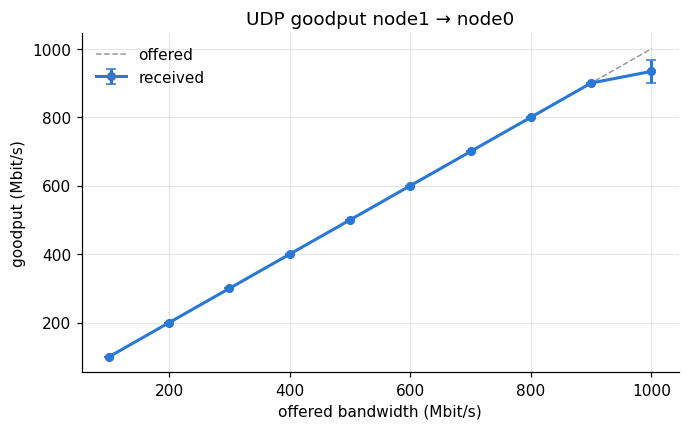

In [4]:
fig, ax = plt.subplots()
ax.plot(
    net['target_mbps'],
    net['target_mbps'],
    color='0.6',
    ls='--',
    lw=1,
    label='offered',
)
ax.errorbar(
    net['target_mbps'],
    net['goodput_mbps_mean'],
    yerr=net['goodput_mbps_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label='received',
)
ax.set(
    xlabel='offered bandwidth (Mbit/s)',
    ylabel='goodput (Mbit/s)',
    title='UDP goodput node1 → node0',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '02_iperf_goodput.png')

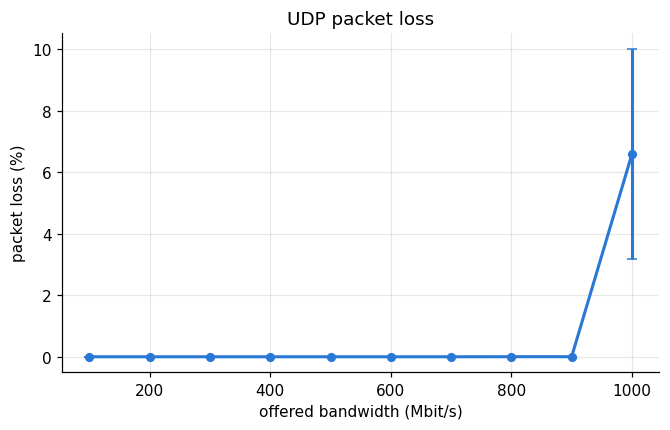

In [5]:
fig, ax = plt.subplots()
ax.errorbar(
    net['target_mbps'],
    net['lost_percent_mean'],
    yerr=net['lost_percent_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
)
ax.set(
    xlabel='offered bandwidth (Mbit/s)',
    ylabel='packet loss (%)',
    title='UDP packet loss',
)
fig.savefig(FIGURES / '02_iperf_loss.png')

## Part 2: Web server (vegeta, 30 s × 10 runs per rate)

In [6]:
single = load_single_node()
cols = [
    'achieved_rate',
    'throughput',
    'success',
    'lat_mean_ms',
    'lat_p50_ms',
    'lat_p90_ms',
    'lat_p99_ms',
    'lat_max_ms',
    'server_cpu',
    'server_usr',
    'server_sys',
]
web = summarize(single, 'rate', cols)
web[['rate'] + [c for c in web.columns if c.endswith(('_mean', '_ci95'))]]

,rate,achieved_rate_mean,achieved_rate_ci95,throughput_mean,throughput_ci95,success_mean,success_ci95,lat_mean_ms_mean,lat_mean_ms_ci95,lat_p50_ms_mean,...,lat_p99_ms_mean,lat_p99_ms_ci95,lat_max_ms_mean,lat_max_ms_ci95,server_cpu_mean,server_cpu_ci95,server_usr_mean,server_usr_ci95,server_sys_mean,server_sys_ci95
0,1000,1000.028,0.009,1000.019,0.009,1.000,0.000,0.242,0.003,0.229,...,0.507,0.010,1.620,0.209,8.456,0.198,2.341,0.151,6.115,0.181
1,2000,2000.038,0.021,2000.022,0.020,1.000,0.000,0.262,0.002,0.240,...,0.677,0.006,1.823,0.244,16.390,0.196,4.728,0.204,11.662,0.126
2,3000,3000.055,0.031,3000.028,0.024,1.000,0.000,0.320,0.003,0.285,...,0.781,0.006,2.108,0.706,23.554,0.214,6.831,0.274,16.723,0.202
3,4000,4000.043,0.064,4000.006,0.063,1.000,0.000,0.356,0.006,0.312,...,0.846,0.007,2.115,0.506,30.252,1.155,8.547,0.489,21.705,0.973
4,5000,5000.015,0.084,4999.969,0.081,1.000,0.000,0.348,0.001,0.269,...,0.918,0.006,2.484,0.727,38.962,0.432,11.025,0.422,27.938,0.433
5,6000,6000.037,0.043,5999.998,0.041,1.000,0.000,0.276,0.003,0.202,...,0.953,0.009,2.869,0.636,47.525,0.350,13.565,0.198,33.960,0.365
6,7000,7000.049,0.013,6999.996,0.021,1.000,0.000,0.266,0.003,0.209,...,0.718,0.010,3.935,0.313,55.692,0.841,15.446,0.594,40.245,0.542
7,8000,8000.027,0.024,7999.947,0.033,1.000,0.000,0.298,0.004,0.236,...,0.759,0.009,5.593,1.509,62.222,0.544,17.075,0.426,45.147,0.558
8,9000,9000.034,0.030,8999.931,0.028,1.000,0.000,0.365,0.017,0.318,...,0.876,0.043,10.811,2.157,61.624,2.486,17.099,0.854,44.525,1.741
9,10000,9999.991,0.047,9999.880,0.065,1.000,0.000,1.215,0.076,0.327,...,12.652,0.897,35.874,4.068,48.505,0.384,13.396,0.275,35.108,0.305


In [7]:
saturation = saturation_rate(web, tolerance=SATURATION_TOLERANCE)
capacity = {
    f'p99 <= {slo} ms': slo_capacity(web, 'lat_p99_ms_mean', slo)
    for slo in SLOS_MS
}
print(
    f'saturation (throughput >= {SATURATION_TOLERANCE:.0%} of offered): {saturation} req/s'
)
capacity

saturation (throughput >= 95% of offered): None req/s


{'p99 <= 1 ms': 9000, 'p99 <= 10 ms': 9000, 'p99 <= 100 ms': 18000}

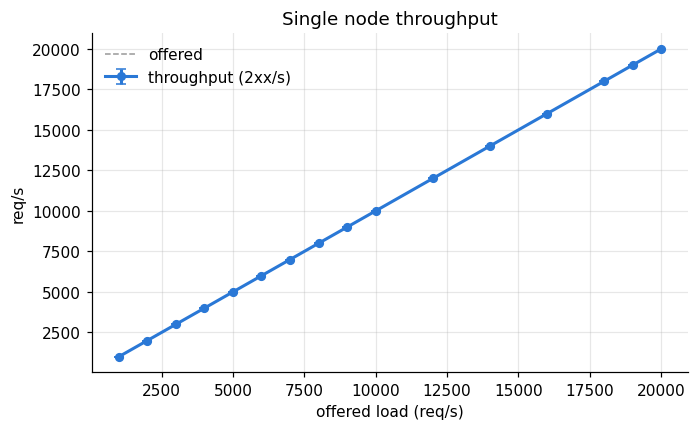

In [8]:
fig, ax = plt.subplots()
ax.plot(web['rate'], web['rate'], color='0.6', ls='--', lw=1, label='offered')
ax.errorbar(
    web['rate'],
    web['throughput_mean'],
    yerr=web['throughput_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label='throughput (2xx/s)',
)
if saturation is not None:
    ax.axvline(saturation, color='0.4', lw=1, ls=':')
    ax.annotate(
        f'saturation {saturation}',
        (saturation, 0),
        xytext=(4, 6),
        textcoords='offset points',
        color='0.3',
    )
ax.set(
    xlabel='offered load (req/s)',
    ylabel='req/s',
    title='Single node throughput',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '02_throughput.png')

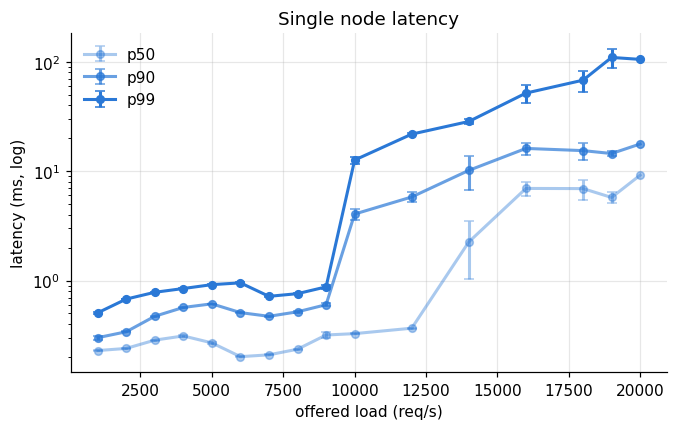

In [9]:
fig, ax = plt.subplots()
for col, shade in [
    ('lat_p50_ms', 0.4),
    ('lat_p90_ms', 0.7),
    ('lat_p99_ms', 1.0),
]:
    ax.errorbar(
        web['rate'],
        web[f'{col}_mean'],
        yerr=web[f'{col}_ci95'],
        color=SINGLE,
        alpha=shade,
        lw=2,
        marker='o',
        ms=5,
        capsize=3,
        label=col.split('_')[1],
    )
ax.set(
    yscale='log',
    xlabel='offered load (req/s)',
    ylabel='latency (ms, log)',
    title='Single node latency',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '02_latency.png')

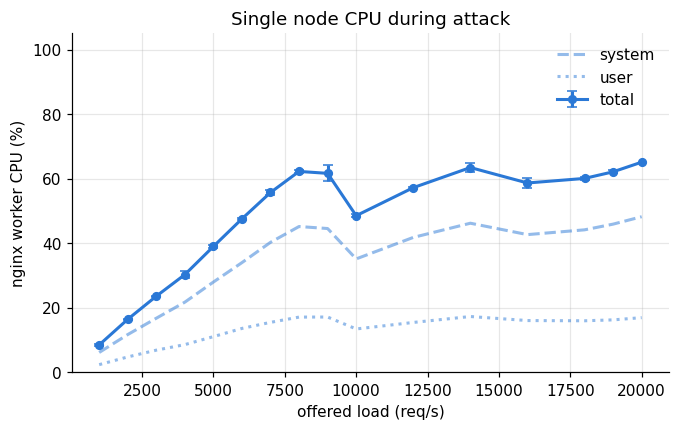

In [10]:
fig, ax = plt.subplots()
ax.errorbar(
    web['rate'],
    web['server_cpu_mean'],
    yerr=web['server_cpu_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label='total',
)
ax.plot(
    web['rate'],
    web['server_sys_mean'],
    color=SINGLE,
    alpha=0.5,
    lw=2,
    ls='--',
    label='system',
)
ax.plot(
    web['rate'],
    web['server_usr_mean'],
    color=SINGLE,
    alpha=0.5,
    lw=2,
    ls=':',
    label='user',
)
ax.set(
    xlabel='offered load (req/s)',
    ylabel='nginx worker CPU (%)',
    ylim=(0, 105),
    title='Single node CPU during attack',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '02_cpu.png')

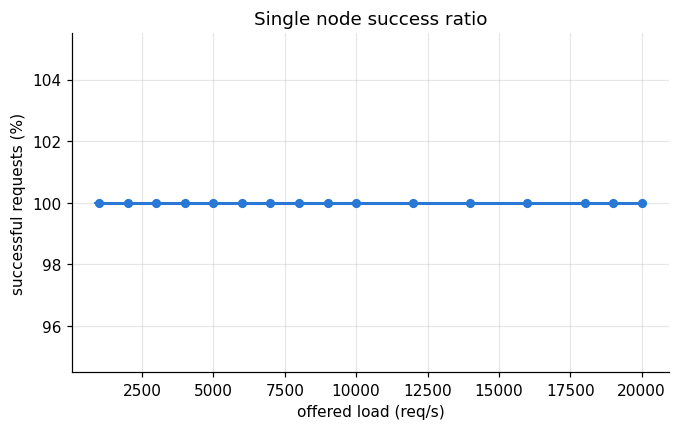

In [11]:
fig, ax = plt.subplots()
ax.errorbar(
    web['rate'],
    100 * web['success_mean'],
    yerr=100 * web['success_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
)
ax.set(
    xlabel='offered load (req/s)',
    ylabel='successful requests (%)',
    title='Single node success ratio',
)
fig.savefig(FIGURES / '02_success.png')

## Is the network the bottleneck?

In [12]:
body_mbps = (
    (single['bytes_in'] * 8 / single['duration_s'] / 1e6)
    .groupby(single['rate'])
    .mean()
)
link_mbps = net['goodput_mbps_mean'].max()
pd.DataFrame({'body_mbps': body_mbps, 'share_of_link': body_mbps / link_mbps})

,body_mbps,share_of_link
rate,,
1000,0.176,0.000
2000,0.352,0.000
3000,0.528,0.001
4000,0.704,0.001
5000,0.880,0.001
6000,1.056,0.001
7000,1.232,0.001
8000,1.408,0.002
9000,1.584,0.002
